In [1]:
%pip install -q gdown

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
from pathlib import Path
from PIL import Image
from tqdm import tqdm

In [4]:
import os
import gdown

FILE_ID = "1nmAPGD8EOjVIS1BZ3fiVHNZDw5Q4HiIl"
ZIP_PATH = "/kaggle/working/pneumonia_dataset.zip"

gdown.download(id=FILE_ID, output=ZIP_PATH, quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1nmAPGD8EOjVIS1BZ3fiVHNZDw5Q4HiIl
From (redirected): https://drive.google.com/uc?id=1nmAPGD8EOjVIS1BZ3fiVHNZDw5Q4HiIl&confirm=t&uuid=15414d87-6547-4047-b284-b4423e55016f
To: /kaggle/working/pneumonia_dataset.zip
100%|██████████| 2.46G/2.46G [00:34<00:00, 72.4MB/s]


'/kaggle/working/pneumonia_dataset.zip'

In [6]:
import os
import zipfile
from pathlib import Path
from tqdm.auto import tqdm

ZIP_PATH = Path("/kaggle/working/pneumonia_dataset.zip")      # hasil download gdown
OUTPUT_DIR = Path("/kaggle/working/Pneumonia/dataset")

assert ZIP_PATH.exists(), f"Zip tidak ditemukan: {ZIP_PATH} (jalankan cell download dulu)"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH) as zf:
    members = zf.infolist()
    for m in tqdm(members, desc="Ekstrak"):
        # Lewati sampah macOS
        if m.filename.startswith("__MACOSX") or m.filename.endswith(".DS_Store"):
            continue
        zf.extract(m, OUTPUT_DIR)

print("Selesai ->", OUTPUT_DIR)

Ekstrak:   0%|          | 0/17591 [00:00<?, ?it/s]

Selesai -> /kaggle/working/Pneumonia/dataset


# X. Check the Dataset

In [7]:
import os
from pathlib import Path

ROOT = Path("/kaggle/working")
DATASET_DIR = ROOT / "Pneumonia" / "dataset" / "chest_xray"
TRAIN_DIR = DATASET_DIR / "train"
EXT = (".jpg", ".jpeg", ".png")

def long_path(p):          # di Linux cukup jadikan string
    return str(p)

def count_images(folder):
    return sum(1 for f in os.listdir(long_path(folder)) if f.lower().endswith(EXT))

assert TRAIN_DIR.is_dir(), f"Folder tidak ditemukan: {TRAIN_DIR}"
print("Dataset:", DATASET_DIR)

total = 0
for kelas in ["NORMAL", "PNEUMONIA"]:
    jumlah = count_images(TRAIN_DIR / kelas)
    total += jumlah
    print(f"{kelas:<10}: {jumlah} foto")

print(f"{'TOTAL':<10}: {total} foto")

Dataset: /kaggle/working/Pneumonia/dataset/chest_xray
NORMAL    : 1341 foto
PNEUMONIA : 3875 foto
TOTAL     : 5216 foto


In [8]:
import os
from pathlib import Path

ROOT = Path("/kaggle/working")
DATASET_DIR = ROOT / "Pneumonia" / "dataset" / "chest_xray"
TEST_DIR = DATASET_DIR / "test"
EXT = (".jpg", ".jpeg", ".png")

def long_path(p):          # di Linux cukup jadikan string
    return str(p)

def count_images(folder):
    return sum(1 for f in os.listdir(long_path(folder)) if f.lower().endswith(EXT))

assert TEST_DIR.is_dir(), f"Folder tidak ditemukan: {TEST_DIR}"
print("Dataset:", DATASET_DIR)

total = 0
for kelas in ["NORMAL", "PNEUMONIA"]:
    jumlah = count_images(TEST_DIR / kelas)
    total += jumlah
    print(f"{kelas:<10}: {jumlah} foto")

print(f"{'TOTAL':<10}: {total} foto")

Dataset: /kaggle/working/Pneumonia/dataset/chest_xray
NORMAL    : 234 foto
PNEUMONIA : 390 foto
TOTAL     : 624 foto


# 1. Read Dataset

In [13]:
import os
import numpy as np
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working")
DATASET_DIR = ROOT / "Pneumonia" / "dataset" / "chest_xray"
# Kalau pakai dataset bawaan Kaggle (Add Input):
# DATASET_DIR = Path("/kaggle/input/chest-xray-pneumonia/chest_xray")

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR  = DATASET_DIR / "test"

IMG_SIZE = (224, 224)
EXT = (".jpg", ".jpeg", ".png")
CLASSES = ["NORMAL", "PNEUMONIA"]          # NORMAL = 0, PNEUMONIA = 1

def long_path(p):          # di Linux cukup jadikan string
    return str(p)

def load_images(data_dir, img_size=IMG_SIZE, mode="RGB"):
    """Baca semua gambar di data_dir/<kelas>. mode: 'RGB' atau 'L' (grayscale)."""
    data_dir = Path(data_dir)
    X, y, paths = [], [], []
    for label, kelas in enumerate(CLASSES):
        folder = data_dir / kelas
        files = sorted(f for f in os.listdir(long_path(folder)) if f.lower().endswith(EXT))
        for fname in tqdm(files, desc=f"{data_dir.name}/{kelas}"):
            fpath = folder / fname
            with Image.open(long_path(fpath)) as img:
                img = img.convert(mode).resize(img_size)
                X.append(np.asarray(img, dtype=np.uint8))
            y.append(label)
            paths.append(str(fpath))
    return np.array(X), np.array(y), paths

assert TRAIN_DIR.is_dir() and TEST_DIR.is_dir(), f"Folder tidak ditemukan di {DATASET_DIR}"

# Train dan test dibaca sendiri-sendiri
X_train, label_train, train_paths = load_images(TRAIN_DIR)
X_test,  label_test,  test_paths  = load_images(TEST_DIR)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)
print("Distribusi train:", dict(zip(CLASSES, np.bincount(y_train))))
print("Distribusi test :", dict(zip(CLASSES, np.bincount(y_test))))

train/NORMAL:   0%|          | 0/1341 [00:00<?, ?it/s]

train/PNEUMONIA:   0%|          | 0/3875 [00:00<?, ?it/s]

test/NORMAL:   0%|          | 0/234 [00:00<?, ?it/s]

test/PNEUMONIA:   0%|          | 0/390 [00:00<?, ?it/s]

X_train: (5216, 224, 224, 3) | y_train: (5216,)
X_test : (624, 224, 224, 3) | y_test : (624,)
Distribusi train: {'NORMAL': np.int64(1341), 'PNEUMONIA': np.int64(3875)}
Distribusi test : {'NORMAL': np.int64(234), 'PNEUMONIA': np.int64(390)}


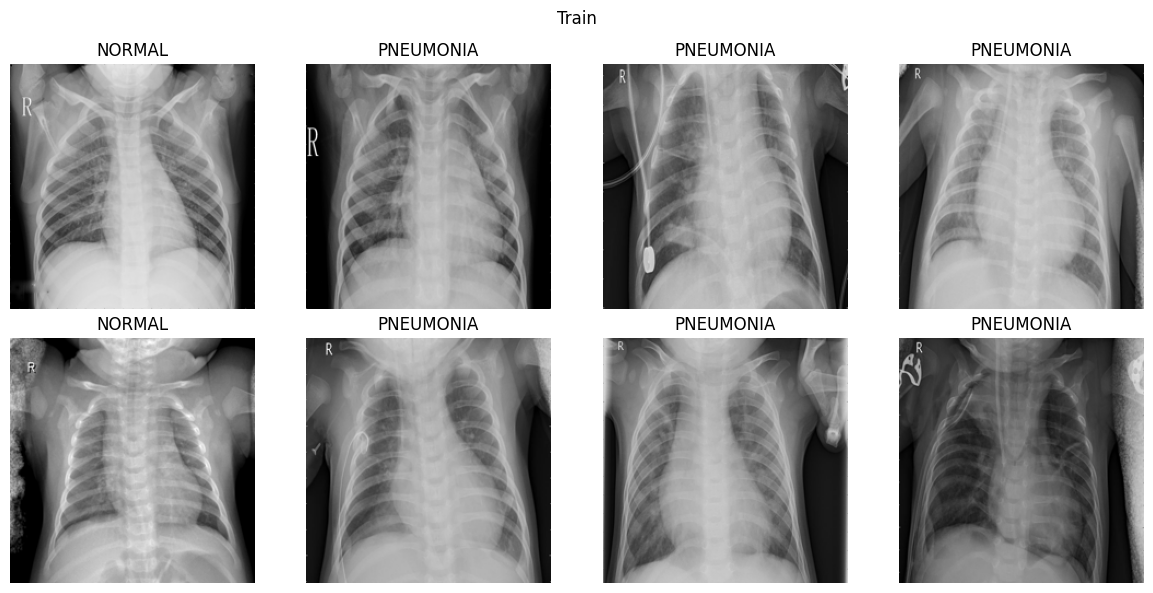

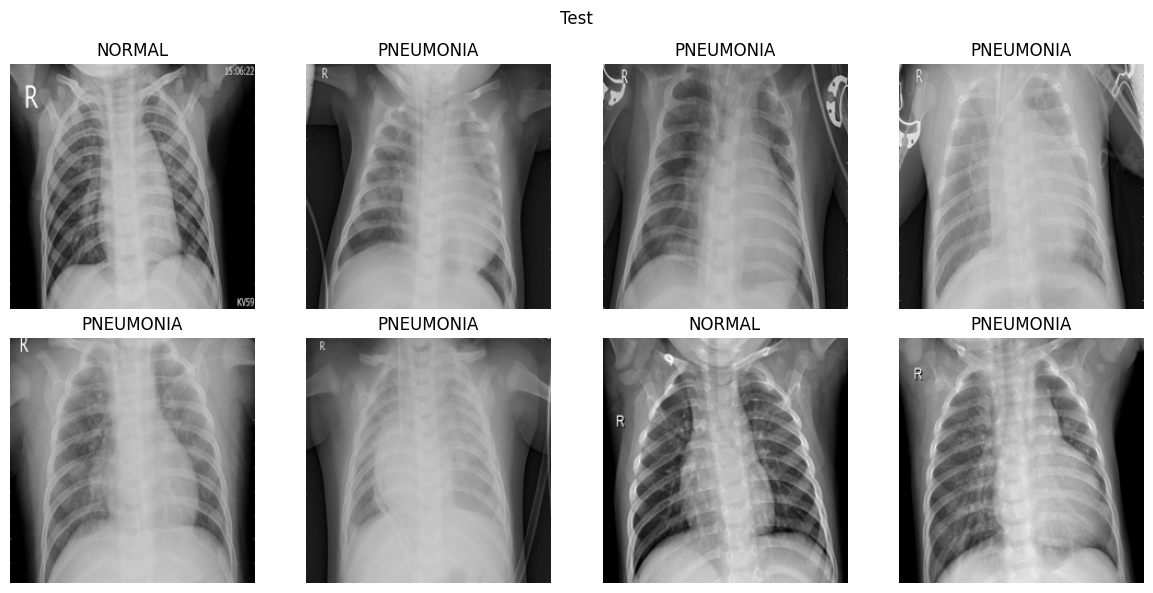

In [14]:
import matplotlib.pyplot as plt

def show_samples(X, y, title, n=8):
    fig, axes = plt.subplots(2, n // 2, figsize=(12, 6))
    fig.suptitle(title)
    for ax in axes.flat:
        i = np.random.randint(len(X))
        ax.imshow(X[i])
        ax.set_title(CLASSES[y[i]])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(X_train, y_train, "Train")
show_samples(X_test, y_test, "Test")

# 2. Modeling

In [35]:
#configuration

import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

SEED = 42
BATCH_SIZE = 32
EPOCHS = 50
LR = 1e-3
PATIENCE = 4                     
SAVE_PATH = ROOT / "Pneumonia" / "densenet121_best.pth"

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [36]:
#split data
X_tr, X_val, label_tr, label_val = train_test_split(
    X_train, label_train, test_size=0.2, stratify=label_train, random_state=SEED
)

In [37]:
class XrayDataset(Dataset):
    def __init__(self, X, y):
        self.X, self.y = X, y
        self.norm = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                         std=[0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        img = torch.from_numpy(self.X[i]).permute(2, 0, 1).float() / 255.0   # HWC -> CHW, 0-1
        return self.norm(img), int(self.y[i])

train_loader = DataLoader(XrayDataset(X_tr, label_tr),   batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(XrayDataset(X_val, label_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(XrayDataset(X_test, label_test), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# Class weight untuk data tidak seimbang
counts = np.bincount(label_tr)
class_weights = torch.tensor(len(label_tr) / (len(counts) * counts), dtype=torch.float32)
print("Train:", len(label_tr), "| Val:", len(label_val), "| Test:", len(label_test))
print("Class weights:", dict(zip(CLASSES, class_weights.numpy().round(3))))

Train: 4172 | Val: 1044 | Test: 624
Class weights: {'NORMAL': np.float32(1.944), 'PNEUMONIA': np.float32(0.673)}


In [38]:
model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)

# 1. Bekukan seluruh backbone pretrained
for p in model.parameters():
    p.requires_grad = False

# 2. Buka (unfreeze) 1 layer terakhir: denselayer16 di denseblock4 + norm5
for p in model.features.denseblock4.denselayer16.parameters():
    p.requires_grad = True
for p in model.features.norm5.parameters():
    p.requires_grad = True

# 3. Classifier baru (otomatis trainable)
model.classifier = nn.Linear(model.classifier.in_features, 2)

model = model.to(device)

# Cek bagian mana yang trainable
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable:,} / {total:,}")

for name, p in model.named_parameters():
    if p.requires_grad:
        print("trainable:", name)

# Loss
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

# Optimizer: learning rate kecil untuk layer pretrained, lebih besar untuk classifier baru
optimizer = optim.Adam([
    {"params": model.features.denseblock4.denselayer16.parameters(), "lr": 1e-5},
    {"params": model.features.norm5.parameters(),                    "lr": 1e-5},
    {"params": model.classifier.parameters(),                        "lr": 1e-3},
])

# Simpan ke file baru supaya model lama tidak tertimpa
SAVE_PATH = ROOT / "densenet121_unfreeze1_best.pth"

Trainable: 170,178 / 6,955,906
trainable: features.denseblock4.denselayer16.norm1.weight
trainable: features.denseblock4.denselayer16.norm1.bias
trainable: features.denseblock4.denselayer16.conv1.weight
trainable: features.denseblock4.denselayer16.norm2.weight
trainable: features.denseblock4.denselayer16.norm2.bias
trainable: features.denseblock4.denselayer16.conv2.weight
trainable: features.norm5.weight
trainable: features.norm5.bias
trainable: classifier.weight
trainable: classifier.bias


In [39]:
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

best_val_loss = float("inf")
best_state = None
wait = 0

for epoch in range(1, EPOCHS + 1):

    # ==================== TRAINING ====================
    model.train()
    model.features.eval()       # backbone tetap eval (BatchNorm tidak berubah)

    train_loss_total = 0.0
    train_correct = 0
    train_n = 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [train]", leave=False)

    for images, labels in train_bar:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_n += images.size(0)

        # Tampilkan loss dan akurasi berjalan di samping progress bar
        train_bar.set_postfix(loss=f"{train_loss_total / train_n:.4f}",
                              acc=f"{train_correct / train_n:.4f}")

    train_loss = train_loss_total / train_n
    train_acc = train_correct / train_n

    # ==================== VALIDASI ====================
    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_n = 0

    val_bar = tqdm(val_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [val]  ", leave=False)

    with torch.no_grad():
        for images, labels in val_bar:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_n += images.size(0)

            val_bar.set_postfix(loss=f"{val_loss_total / val_n:.4f}",
                                acc=f"{val_correct / val_n:.4f}")

    val_loss = val_loss_total / val_n
    val_acc = val_correct / val_n

    # ==================== CATAT & TAMPILKAN ====================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/{EPOCHS} | "
          f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    # ==================== SIMPAN MODEL TERBAIK ====================
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, SAVE_PATH)
        wait = 0
        print("  -> model terbaik disimpan")
    else:
        wait += 1
        print(f"  -> tidak membaik ({wait}/{PATIENCE})")
        if wait >= PATIENCE:
            print(f"Early stopping di epoch {epoch}")
            break

model.load_state_dict(best_state)
print("Model terbaik dimuat. Val loss:", round(best_val_loss, 4))

Epoch 01/50 [train]:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch 01/50 [val]  :   0%|          | 0/33 [00:00<?, ?it/s]

Epoch 01/50 | train loss 0.2763 acc 0.8967 | val loss 0.1739 acc 0.9550
  -> model terbaik disimpan


Epoch 02/50 [train]:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch 02/50 [val]  :   0%|          | 0/33 [00:00<?, ?it/s]

Epoch 02/50 | train loss 0.1362 acc 0.9465 | val loss 0.1294 acc 0.9559
  -> model terbaik disimpan


... (74 outputs left out)

Epoch 27/50 | train loss 0.0168 acc 0.9938 | val loss 0.0873 acc 0.9799
  -> tidak membaik (3/4)


Epoch 28/50 [train]:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch 28/50 [val]  :   0%|          | 0/33 [00:00<?, ?it/s]

Epoch 28/50 | train loss 0.0128 acc 0.9966 | val loss 0.0721 acc 0.9799
  -> tidak membaik (4/4)
Early stopping di epoch 28
Model terbaik dimuat. Val loss: 0.0699


In [40]:
import numpy as np
import torch
from tqdm.auto import tqdm

# Pastikan memakai model terbaik hasil training
model.load_state_dict(torch.load(SAVE_PATH, map_location=device))
model.eval()

all_preds = []      # kelas yang ditebak (0 atau 1)
all_probs = []      # probabilitas PNEUMONIA (untuk ROC-AUC)
all_labels = []     # label asli

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Prediksi test"):
        images = images.to(device)

        outputs = model(images)                      # skor mentah (logits)
        probs = torch.softmax(outputs, dim=1)        # ubah jadi probabilitas
        preds = probs.argmax(dim=1)                  # kelas dengan probabilitas tertinggi

        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs[:, 1].cpu().numpy())  # kolom 1 = PNEUMONIA
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

print("Jumlah prediksi:", len(all_preds))

Prediksi test:   0%|          | 0/20 [00:00<?, ?it/s]

Jumlah prediksi: 624


In [41]:
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score)

print("Accuracy :", round(accuracy_score(all_labels, all_preds), 4))
print("ROC-AUC  :", round(roc_auc_score(all_labels, all_probs), 4))
print()
print(classification_report(all_labels, all_preds, target_names=CLASSES, digits=4))

cm = confusion_matrix(all_labels, all_preds)
print("Confusion matrix:\n", cm)

Accuracy : 0.8189
ROC-AUC  : 0.958

              precision    recall  f1-score   support

      NORMAL     0.9840    0.5256    0.6852       234
   PNEUMONIA     0.7776    0.9949    0.8729       390

    accuracy                         0.8189       624
   macro avg     0.8808    0.7603    0.7791       624
weighted avg     0.8550    0.8189    0.8025       624

Confusion matrix:
 [[123 111]
 [  2 388]]


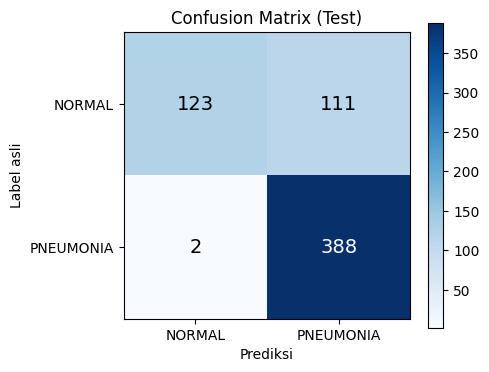

In [42]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1]); ax.set_xticklabels(CLASSES)
ax.set_yticks([0, 1]); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label asli")
ax.set_title("Confusion Matrix (Test)")

# Tulis angka di tiap kotak
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)

plt.colorbar(im)
plt.tight_layout()
plt.show()

Salah prediksi: 113 dari 624 gambar


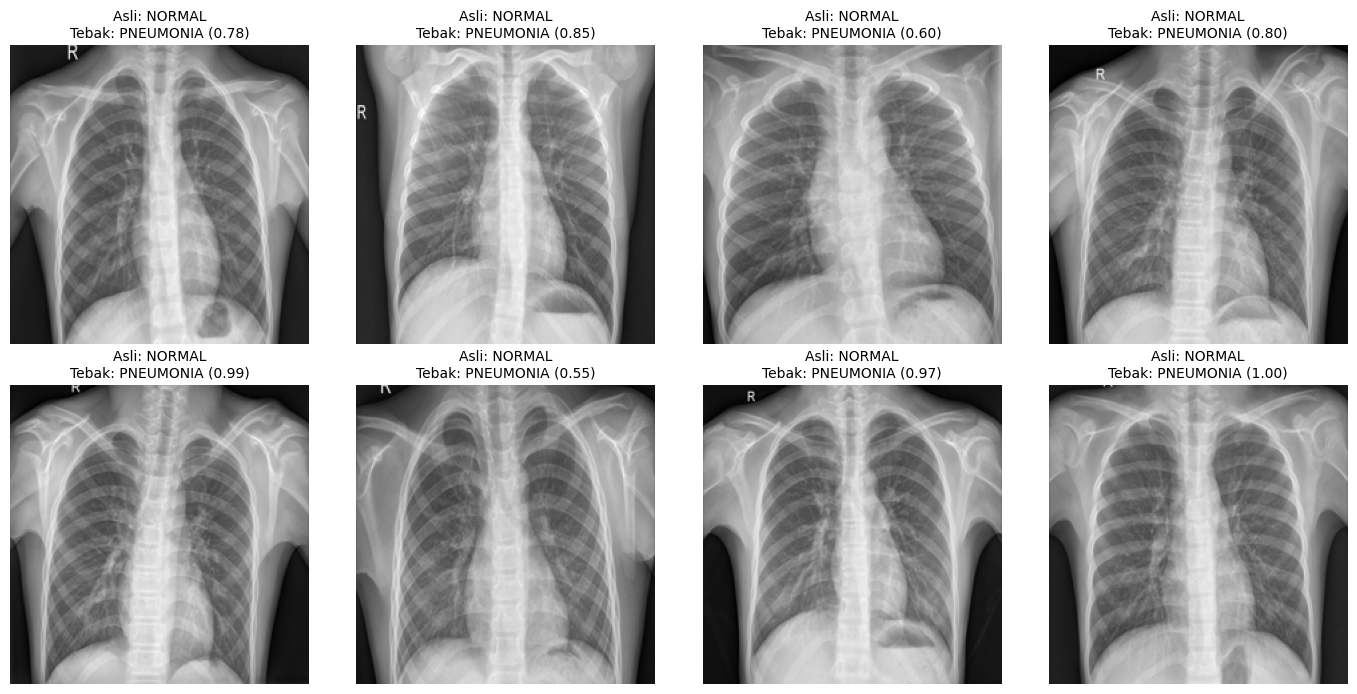

In [43]:
# Cari indeks gambar yang salah tebak
wrong_idx = np.where(all_preds != all_labels)[0]
print(f"Salah prediksi: {len(wrong_idx)} dari {len(all_labels)} gambar")

# Tampilkan maksimal 8 gambar
n_show = min(8, len(wrong_idx))
if n_show > 0:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, wrong_idx[:n_show]):
        ax.imshow(X_test[i])
        ax.set_title(f"Asli: {CLASSES[all_labels[i]]}\n"
                     f"Tebak: {CLASSES[all_preds[i]]} ({all_probs[i]:.2f})", fontsize=10)
    plt.tight_layout()
    plt.show()

In [44]:
import numpy as np

# Pilih contoh: pneumonia benar, normal benar, dan yang salah prediksi
idx_pneu  = np.where((all_labels == 1) & (all_preds == 1))[0][:3]
idx_norm  = np.where((all_labels == 0) & (all_preds == 0))[0][:3]
idx_wrong = np.where(all_preds != all_labels)[0][:3]

selected = list(idx_pneu) + list(idx_norm) + list(idx_wrong)
tags = ["Benar (PNEUMONIA)"] * len(idx_pneu) + \
       ["Benar (NORMAL)"] * len(idx_norm) + \
       ["SALAH"] * len(idx_wrong)
print("Gambar yang ditampilkan:", selected)

Gambar yang ditampilkan: [np.int64(234), np.int64(235), np.int64(236), np.int64(2), np.int64(4), np.int64(5), np.int64(0), np.int64(1), np.int64(3)]


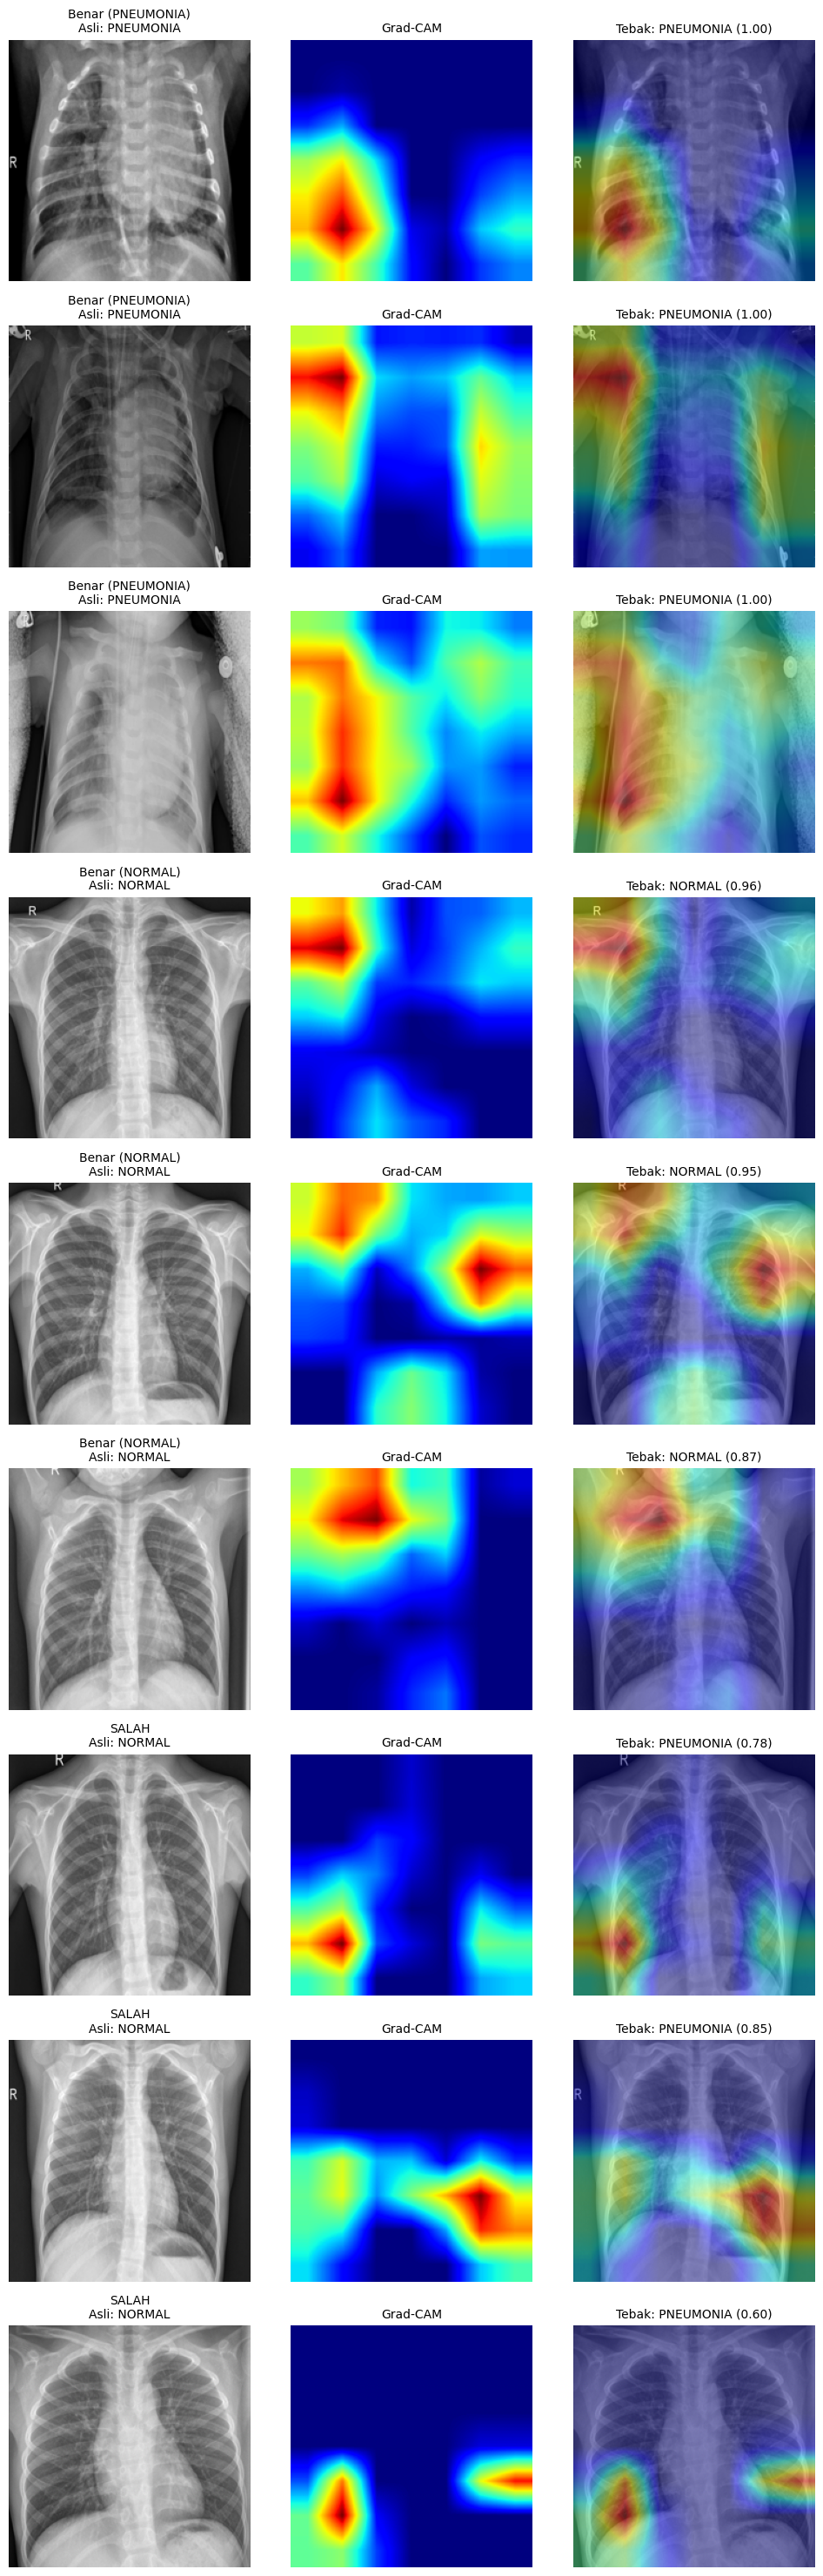

In [45]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib import cm
from torchvision import transforms

normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

model.eval()

fig, axes = plt.subplots(len(selected), 3, figsize=(10, 3.3 * len(selected)))
if len(selected) == 1:
    axes = axes[None, :]

for row, (i, tag) in enumerate(zip(selected, tags)):

    # 1. Siapkan gambar (sama seperti di Dataset)
    img_np = X_test[i]                                            # (224, 224, 3) uint8
    x = torch.from_numpy(img_np).permute(2, 0, 1).float() / 255.0
    x = normalize(x).unsqueeze(0).to(device)
    x.requires_grad_(True)                                        # supaya gradien mengalir ke feature map

    # 2. Forward manual, dipecah supaya kita bisa menangkap feature map
    with torch.enable_grad():
        fmap = model.features(x)                                  # (1, 1024, 7, 7)
        fmap.retain_grad()                                        # simpan gradiennya
        pooled = F.adaptive_avg_pool2d(F.relu(fmap), 1).flatten(1)
        logits = model.classifier(pooled)

        pred_class = logits.argmax(dim=1).item()                  # kelas yang ditebak
        prob = torch.softmax(logits, dim=1)[0, pred_class].item()

        # 3. Backward dari skor kelas yang ditebak
        model.zero_grad()
        logits[0, pred_class].backward()

    # 4. Hitung Grad-CAM
    grads = fmap.grad[0]                                          # (1024, 7, 7)
    weights = grads.mean(dim=(1, 2))                              # bobot tiap channel
    cam_map = (weights[:, None, None] * fmap[0].detach()).sum(dim=0)
    cam_map = F.relu(cam_map)                                     # hanya yang mendukung kelas
    cam_map = cam_map / (cam_map.max() + 1e-8)                    # skala 0-1

    # 5. Perbesar 7x7 -> 224x224
    cam_up = F.interpolate(cam_map[None, None], size=img_np.shape[:2],
                           mode="bilinear", align_corners=False)[0, 0]
    cam_up = cam_up.cpu().numpy()

    # 6. Tempel heatmap di atas gambar asli
    heatmap = cm.jet(cam_up)[:, :, :3]                            # RGB, 0-1
    overlay = 0.55 * (img_np / 255.0) + 0.45 * heatmap
    overlay = np.clip(overlay, 0, 1)

    # 7. Tampilkan
    axes[row, 0].imshow(img_np)
    axes[row, 0].set_title(f"{tag}\nAsli: {CLASSES[all_labels[i]]}", fontsize=10)
    axes[row, 1].imshow(cam_up, cmap="jet")
    axes[row, 1].set_title("Grad-CAM", fontsize=10)
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(f"Tebak: {CLASSES[pred_class]} ({prob:.2f})", fontsize=10)
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()